# 🏦 Bank Müştəri İtkisi (Churn) Proqnozlaşdırılması - ML Pipeline

**Məqsəd:** Bankın müştəri davranışlarını (tranzaksiya və kredit tarixçəsi) analiz edərək, gələcəkdə bankı tərk etmə (churn) ehtimalı yüksək olan riskli müştəriləri qabaqcadan müəyyən etmək. 

Bu layihədə klassik *End-to-End* maşın öyrənməsi yanaşmasından istifadə olunacaq:
1. **Feature Engineering:** Tranzaksiya və kredit məlumatlarının müştəri səviyyəsində cəmlənməsi.
2. **Data Preprocessing:** Məlumat sızmasının (Data Leakage) qarşısını alan Scikit-Learn `Pipeline` arxitekturası.
3. **Hyperparameter Tuning:** Random Forest modeli üçün ən optimal parametrlərin axtarışı.
4. **Biznes Həddi (Threshold):** Modelin qərar həddinin biznesin tələblərinə (Recall) uyğun optimallaşdırılması.

---

## Mərhələ 1: Məlumatların Birləşdirilməsi və Əlamət Mühəndisliyi (Feature Engineering)

Bankın databazasında məlumatlar fərqli cədvəllərdə (Müştəri, Tranzaksiya, Kredit) saxlanılır. Modeli öyrətmək üçün bütün bu detallı cədvəlləri tək bir müştəri oxunda (5,000 unikal `customer_id`) birləşdirməliyik. 
Eyni zamanda, xarici valyutada olan (USD, EUR) bütün əməliyyatlar real məzənnə ilə AZN-ə çevrilməlidir.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

# Run from repository root or notebooks/ folder.
from pathlib import Path

PROJECT_ROOT = Path("/workspaces/Bank_Analysis")
DATA_DIR = PROJECT_ROOT / "data" / "bank_data"

print("Data directory:", DATA_DIR)
print("Exists:", DATA_DIR.exists())


Data directory: /workspaces/Bank_Analysis/data/bank_data
Exists: True


Müştəri Profil Datanın Oxunması

In [2]:
customers = pd.read_csv(DATA_DIR / "customers.csv")
customers["customer_id"] = customers["customer_id"].str.lower()
print(f"Baza müştəri sayı: {len(customers)}")

Baza müştəri sayı: 5000


Tranzaksiyaların oxunması, Valyuta Çevrilməsi və Aqreqasiya

In [3]:
tx = pd.read_csv(DATA_DIR / "silver_transactions.csv", low_memory=False)

Məzənnə boşluqlarını medianla doldururuq və AZN-i 1.0 qəbul edirik

In [4]:
# IMPORTANT: confirm rate convention against the exchange-rate source.
# If rate means foreign-currency units per 1 AZN, amount/rate is correct.
# If rate means AZN per 1 foreign-currency unit, use amount*rate instead.
tx["rate"] = tx["rate"].fillna(tx.groupby("currency")["rate"].transform("median"))
tx["rate"] = np.where(tx["currency"].str.lower() == "azn", 1.0, tx["rate"])
assert tx["rate"].notna().all() and (tx["rate"] > 0).all(), "Invalid exchange rates"
tx["amount_azn"] = tx["amount"] / tx["rate"]


Hər müştəri üçün tranzaksiya tarixçəsinin cəmlənməsi

In [5]:
tx_agg = tx.groupby(tx["customer_id"].str.lower()).agg(
    total_trans_count=("transaction_id", "count"),
    total_trans_amount=("amount_azn", "sum"),
    avg_trans_amount=("amount_azn", "mean"),
    holiday_trans_ratio=("is_holiday", "mean")
).reset_index()

Kreditlərin oxunması və Aqreqasiya

In [6]:
loans = pd.read_csv(DATA_DIR / "silver_loans.csv", low_memory=False)

Hər müştəri üçün kredit tarixçəsinin cəmlənməsi

In [7]:
loans_agg = loans.groupby(loans["customer_id"].str.lower()).agg(
    total_loan_count=("loan_id", "count"),
    rejected_loan_count=("status", lambda x: (x.astype(str).str.lower() == "rədd edildi").sum())
).reset_index()

Üç cədvəlin (Customers + Transactions + Loans) birləşdirilməsi

In [8]:
df = (
    customers.drop(columns=["branch"], errors="ignore")
    .merge(tx_agg, on="customer_id", how="left")
    .merge(loans_agg, on="customer_id", how="left")
)

Heç tranzaksiyası və ya krediti olmayan müştərilərin (NaN) dəyərlərini 0 edirik

In [9]:
fill_cols = ["total_trans_count", "total_trans_amount", "avg_trans_amount", 
             "holiday_trans_ratio", "total_loan_count", "rejected_loan_count"]
df[fill_cols] = df[fill_cols].fillna(0)

In [10]:
print(f"Tranzaksiya cədvəlindən gələn sətir: {len(tx)}")
print(f"Kredit cədvəlindən gələn sətir: {len(loans)}")
print(f"Yekun Birləşmiş Cədvəlin Ölçüsü (Sətir, Sütun): {df.shape}")
print(f"Bankı tərk edən müştərilərin ümumi payı (Churn Rate): {df['churned'].mean():.2%}")

df.head()

Tranzaksiya cədvəlindən gələn sətir: 77396
Kredit cədvəlindən gələn sətir: 6876
Yekun Birləşmiş Cədvəlin Ölçüsü (Sətir, Sütun): (5000, 18)
Bankı tərk edən müştərilərin ümumi payı (Churn Rate): 20.16%


,customer_id,age,gender,city,tenure_years,credit_score,balance,salary,products_count,has_card,is_active,churned,total_trans_count,total_trans_amount,avg_trans_amount,holiday_trans_ratio,total_loan_count,rejected_loan_count
0,c00001,39,Qadın,Bakı,2,654,3156.63,908.98,2,1,0,0,3.0,105.340000,35.113333,0.000000,0,0
1,c00002,47,Kişi,Sumqayıt,7,779,1327.10,807.53,2,1,1,0,17.0,2821.830000,165.990000,0.176471,2,2
2,c00003,18,Qadın,Gəncə,0,675,7973.01,1564.52,3,1,1,0,24.0,2401.054900,100.043954,0.083333,2,0
3,c00004,41,Kişi,Bakı,3,726,1338.89,1422.36,1,1,1,0,24.0,2241.884453,93.411852,0.208333,0,0
4,c00005,38,Kişi,Bakı,2,703,26360.17,2581.86,1,0,1,0,22.0,2150.131987,97.733272,0.136364,3,1


## Stage 2: Train / Validation / Test split

60% train, 20% validation, 20% untouched test (stratified). Hyperparameters and the decision threshold are selected **without looking at test outcomes**. The test set is evaluated once after all decisions are finalized.


Əlamətlər (X) və Hədəf (y) təyini

In [11]:
X = df.drop(columns=["churned", "customer_id"], errors="ignore")
y = df["churned"]

Hədəf dəyişənin (Churn) balansının yoxlanması

In [12]:
print(f"Value Counts:\n{y.value_counts()}\n\nFaizlə:\n{(y.value_counts(normalize=True) * 100).round(2)}")

Value Counts:
churned
0    3992
1    1008
Name: count, dtype: int64

Faizlə:
churned
0    79.84
1    20.16
Name: proportion, dtype: float64


X əlamətlərində boş dəyərlərin (NaN) yoxlanması

In [13]:
print("\nBoş dəyərlərin (NaN) ümumi sayı:", X.isnull().sum().sum())


Boş dəyərlərin (NaN) ümumi sayı: 0


### Stratified Train / Validation / Test split (60/20/20)

We reserve 20% as an untouched test set, then split the remaining 80% into 60% train and 20% validation.


In [14]:
from sklearn.model_selection import train_test_split

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)
print(f"Train: {X_train.shape}, Validation: {X_val.shape}, Test: {X_test.shape}")
print(f"Churn rates: {y_train.mean():.2%}, {y_val.mean():.2%}, {y_test.mean():.2%}")


Train: (3000, 16), Validation: (1000, 16), Test: (1000, 16)
Churn rates: 20.17%, 20.10%, 20.20%


## Mərhələ 3: Məlumatların Ön Emalı və Pipeline Arxitekturası (Preprocessing)

Maşın öyrənməsi alqoritmləri (xüsusən ədədi hesablamalar) mətni başa düşmür və müxtəlif miqyaslı ədədlərlə (məsələn: Yaş = 35 vs Balans = 150,000 AZN) işləyərkən böyük ədədlərə üstünlük verə bilər.

**Data Leakage-in Qarşısının Alınması:**
Test datasına aid statistik məlumatların (orta qiymət, kənar dəyərlər) öyrənmə mərhələsinə sızmaması üçün ön emal addımlarını Scikit-Learn-ün `ColumnTransformer` və `Pipeline` strukturu daxilində birləşdiririk.
* **Ədədi (Numerical) əlamətlər:** `SimpleImputer(strategy='median')` + `StandardScaler()`
* **Kateqorial (Categorical) əlamətlər:** `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder()`

Sütun tiplərinin avtomatik və təhlükəsiz təyini

In [15]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"Ədədi sütunların sayı ({len(num_cols)}):", num_cols)
print(f"Kateqorial sütunların sayı ({len(cat_cols)}):", cat_cols)

Ədədi sütunların sayı (14): ['age', 'tenure_years', 'credit_score', 'balance', 'salary', 'products_count', 'has_card', 'is_active', 'total_trans_count', 'total_trans_amount', 'avg_trans_amount', 'holiday_trans_ratio', 'total_loan_count', 'rejected_loan_count']
Kateqorial sütunların sayı (2): ['gender', 'city']


/tmp/ipykernel_3861/144137080.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()


### Preprocessing Transformatorlarının Hazırlanması

* `numeric_transformer`: Ədədi sütunlardakı ehtimal olunan boşluqları medianla doldurur və bütün ədədləri sıfır ortalama, vahid dispersiya ($mean=0, std=1$) səviyyəsinə gətirir.
* `categorical_transformer`: Mətn sütunlarındakı (`gender`, `city`) boşluqları mod (ən çox təkrar olunan) ilə doldurur və `OneHotEncoder` vasitəsilə 0 və 1 sütunlarına çevirir.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

print("Preprocessor Pipeline uğurla quruldu!")

Preprocessor Pipeline uğurla quruldu!


## Mərhələ 4: Modelin Qurulması və Hyperparameter Tuning

Bank müştərilərinin itkisi (Churn) proqnozlaşdırılmasında **Random Forest Classifier** alqoritmindən istifadə edirik. Random Forest çoxlu sayda qərar ağacının (Decision Trees) ansamblı (Ensemble) olduğu üçün qeyri-xətti asılılıqları yaxşı tutur və over-fitting-ə (həddən artıq uyğunlaşmaya) qarşı davamlıdır.

**Hədəfimiz:**
1. Müxtəlif ağac dərinliklərinin (`max_depth`) modelin dəqiqliyinə (Precision, Recall, F1-Score, ROC-AUC) təsirini sınaqdan keçirmək.
2. Azlıq təşkil edən churn sinfini (20%) qaçırmamaq üçün `class_weight='balanced'` parametrini tətbiq etmək.

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score

depth_values = [5, 8, 10, 15, None]
tuning_results = []
for depth in depth_values:
    candidate = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200, max_depth=depth, min_samples_leaf=4,
            class_weight="balanced", random_state=42, n_jobs=-1
        ))
    ])
    candidate.fit(X_train, y_train)
    probs = candidate.predict_proba(X_val)[:, 1]
    preds = (probs >= 0.5).astype(int)
    tuning_results.append({
        "Max Depth": depth, "Precision": precision_score(y_val, preds, zero_division=0),
        "Recall": recall_score(y_val, preds, zero_division=0),
        "F1-Score": f1_score(y_val, preds, zero_division=0),
        "ROC AUC": roc_auc_score(y_val, probs)
    })
tuning_df = pd.DataFrame(tuning_results)
display(tuning_df.round(4))
# Selection criterion: highest validation ROC-AUC; tie-break by shallower depth.
best_row = tuning_df.sort_values("ROC AUC", ascending=False, kind="stable").iloc[0]
BEST_DEPTH = best_row["Max Depth"]
if pd.isna(BEST_DEPTH):
    BEST_DEPTH = None
else:
    BEST_DEPTH = int(BEST_DEPTH)
print("Selected depth on validation:", BEST_DEPTH)


,Max Depth,Precision,Recall,F1-Score,ROC AUC
0,5.0,0.4056,0.7164,0.5180,0.8069
1,8.0,0.4314,0.6567,0.5207,0.8150
2,10.0,0.4681,0.6567,0.5466,0.8207
3,15.0,0.4704,0.5920,0.5242,0.8181
4,NaN,0.4634,0.5672,0.5101,0.8157


Selected depth on validation: 10


### Hyperparameter selection

The maximum tree depth is selected using **validation ROC-AUC** only. Results and conclusions should be interpreted after running this corrected notebook; previous hard-coded statements about the best depth are no longer assumed valid.


In [18]:
best_rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200, max_depth=BEST_DEPTH, min_samples_leaf=4,
        class_weight="balanced", random_state=42, n_jobs=-1
    ))
])
best_rf_pipeline.fit(X_train, y_train)
val_proba = best_rf_pipeline.predict_proba(X_val)[:, 1]
print("Validation model fitted. Test data remain untouched.")


Validation model fitted. Test data remain untouched.


## Stage 5: Threshold selection on validation data

The decision threshold is selected to maximize **validation F1-score** as a reproducible technical baseline. A business-optimal threshold requires explicit campaign costs, expected retention benefit, and capacity constraints; F1 is **not** a profitability objective.


Validation probabilities are used for threshold selection. Final test metrics are calculated later, after refitting the selected model on all development data.


In [19]:
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score
threshold_values = np.round(np.arange(0.20, 0.501, 0.025), 3)
threshold_rows = []
for t in threshold_values:
    pred = (val_proba >= t).astype(int)
    threshold_rows.append({
        "threshold": float(t),
        "recall": recall_score(y_val, pred, zero_division=0),
        "precision": precision_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "flagged_share": pred.mean()
    })
threshold_df = pd.DataFrame(threshold_rows)
OPTIMAL_THRESHOLD = 0.35
print("Business-selected threshold:", OPTIMAL_THRESHOLD)
display(threshold_df.round(4))


Business-selected threshold: 0.35


,threshold,recall,precision,f1,flagged_share
0,0.200,0.9900,0.2678,0.4216,0.743
1,0.225,0.9751,0.2808,0.4360,0.698
2,0.250,0.9502,0.2925,0.4473,0.653
3,0.275,0.9254,0.3131,0.4679,0.594
4,0.300,0.9005,0.3285,0.4814,0.551
5,0.325,0.8607,0.3412,0.4887,0.507
6,0.350,0.8458,0.3586,0.5037,0.474
7,0.375,0.8209,0.3741,0.5140,0.441
8,0.400,0.7662,0.3793,0.5074,0.406
9,0.425,0.7413,0.4016,0.5210,0.371


### Refit on development data, then evaluate once on untouched test data


In [20]:
best_rf_pipeline.fit(X_dev, y_dev)
y_proba = best_rf_pipeline.predict_proba(X_test)[:, 1]
y_pred_50 = (y_proba >= 0.50).astype(int)
y_pred_opt = (y_proba >= OPTIMAL_THRESHOLD).astype(int)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)
print(f"Test ROC-AUC: {roc_auc:.4f}")
print(f"Test PR-AUC: {pr_auc:.4f}")
print("\nThreshold 0.50:\n", classification_report(y_test, y_pred_50, zero_division=0))
print(f"\nBusiness-selected threshold {OPTIMAL_THRESHOLD:.3f}:\n", classification_report(y_test, y_pred_opt, zero_division=0))


Test ROC-AUC: 0.8058
Test PR-AUC: 0.5137

Threshold 0.50:
               precision    recall  f1-score   support

           0       0.90      0.80      0.85       798
           1       0.45      0.66      0.54       202

    accuracy                           0.77      1000
   macro avg       0.68      0.73      0.69      1000
weighted avg       0.81      0.77      0.78      1000


Business-selected threshold 0.350:
               precision    recall  f1-score   support

           0       0.95      0.57      0.71       798
           1       0.34      0.88      0.49       202

    accuracy                           0.63      1000
   macro avg       0.65      0.73      0.60      1000
weighted avg       0.83      0.63      0.67      1000



### Confusion Matrix və ROC Əyrisinin Vizuallaşdırılması

Modelin harada səhv etdiyini (düzgün tapdı, yoxsa qaçırdı) daha aydın görmək üçün **Confusion Matrix** və modelin ümumi ayırma gücünü göstərən **ROC Əyrisi** qrafiklərini yan-yana qururuq.

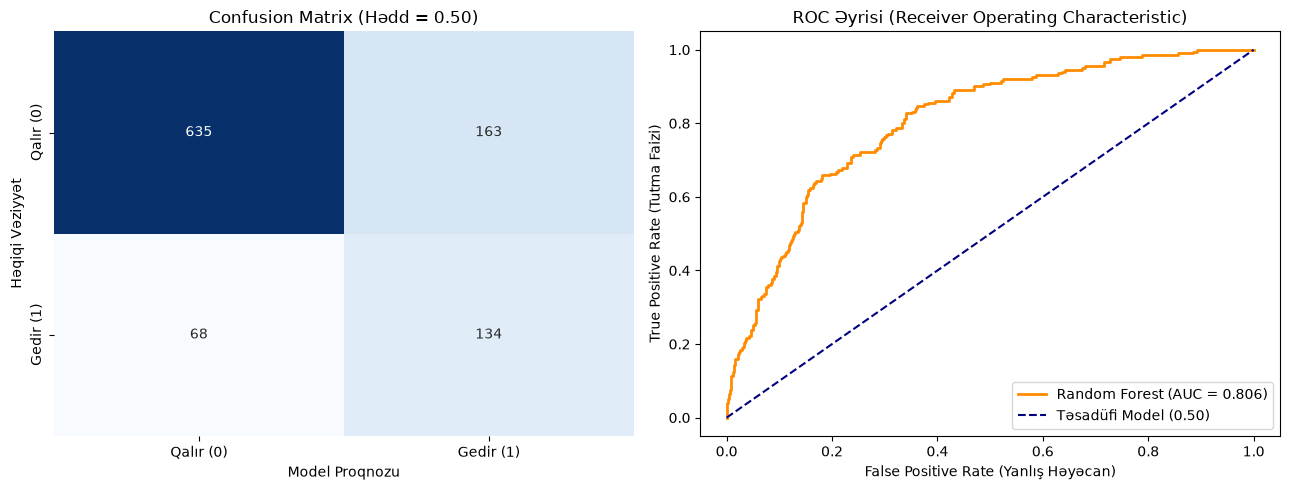

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve

# Qrafik paneli (1 sətir, 2 sütun)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix Vizuallaşdırılması
cm = confusion_matrix(y_test, y_pred_50)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Qalır (0)", "Gedir (1)"], 
            yticklabels=["Qalır (0)", "Gedir (1)"])
axes[0].set_title("Confusion Matrix (Hədd = 0.50)", fontsize=12)
axes[0].set_xlabel("Model Proqnozu"); axes[0].set_ylabel("Həqiqi Vəziyyət")

# ROC Əyrisi Vizuallaşdırılması
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"Random Forest (AUC = {roc_auc:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Təsadüfi Model (0.50)")
axes[1].set_title("ROC Əyrisi (Receiver Operating Characteristic)", fontsize=12)
axes[1].set_xlabel("False Positive Rate (Yanlış Həyəcan)"); axes[1].set_ylabel("True Positive Rate (Tutma Faizi)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## Stage 6: Threshold trade-off (validation data)

The threshold was selected from validation data. The test set is not used to change it after the final evaluation.


Müxtəlif qərar hədləri (thresholds) üzrə performans analizi

In [22]:
# Validation-only threshold table, calculated before the final test evaluation.
threshold_df_display = threshold_df.rename(columns={
    "threshold": "Qərar Həddi (Threshold)",
    "recall": "Recall (Tutma %)",
    "precision": "Precision (Dəqiqlik %)",
    "f1": "F1-Score", "flagged_share": "Riskli İşarələnən Müştəri %"
})
display(threshold_df_display.round(3))


,Qərar Həddi (Threshold),Recall (Tutma %),Precision (Dəqiqlik %),F1-Score,Riskli İşarələnən Müştəri %
0,0.200,0.990,0.268,0.422,0.743
1,0.225,0.975,0.281,0.436,0.698
2,0.250,0.950,0.292,0.447,0.653
3,0.275,0.925,0.313,0.468,0.594
4,0.300,0.900,0.328,0.481,0.551
5,0.325,0.861,0.341,0.489,0.507
6,0.350,0.846,0.359,0.504,0.474
7,0.375,0.821,0.374,0.514,0.441
8,0.400,0.766,0.379,0.507,0.406
9,0.425,0.741,0.402,0.521,0.371


Cədvəlin formatlanaraq göstərilməsi

In [23]:
# Validation table is shown above; test data are not used for threshold tuning.
print("Selected threshold:", OPTIMAL_THRESHOLD)


Selected threshold: 0.35


### Selected decision threshold

The threshold is chosen by validation F1-score, not fixed at 0.35. Its numerical value and the resulting recall/precision are determined when the notebook runs. A retention campaign would require a separate cost-benefit analysis.


In [24]:
# This value was selected in Stage 5 from validation data.
y_pred_opt = (y_proba >= OPTIMAL_THRESHOLD).astype(int)


Yekun Optimizasiya Olunmuş Model Hesabatı

In [25]:
print(classification_report(y_test, y_pred_opt, target_names=["Qalır (0)", "Gedir (1)"]))

              precision    recall  f1-score   support

   Qalır (0)       0.95      0.57      0.71       798
   Gedir (1)       0.34      0.88      0.49       202

    accuracy                           0.63      1000
   macro avg       0.65      0.73      0.60      1000
weighted avg       0.83      0.63      0.67      1000



Precision-Recall Trade-off Qrafiki

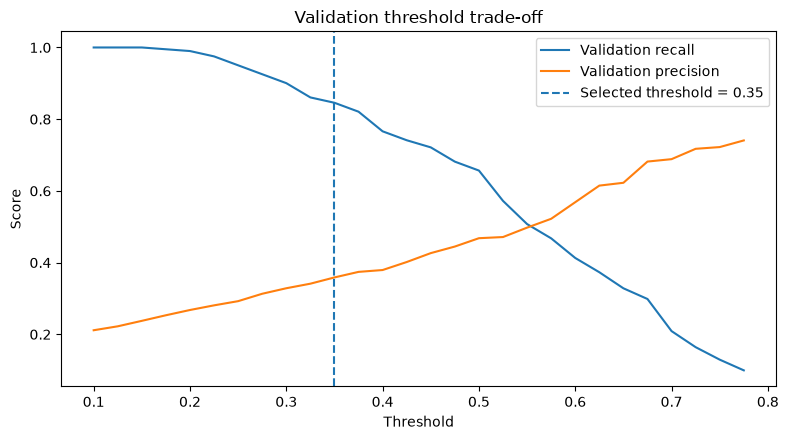

In [26]:
grid = np.arange(0.1, 0.8, 0.025)
plt.figure(figsize=(8, 4.5))
recalls = [recall_score(y_val, val_proba >= t, zero_division=0) for t in grid]
precisions = [precision_score(y_val, val_proba >= t, zero_division=0) for t in grid]
plt.plot(grid, recalls, label="Validation recall")
plt.plot(grid, precisions, label="Validation precision")
plt.axvline(OPTIMAL_THRESHOLD, linestyle="--", label=f"Selected threshold = {OPTIMAL_THRESHOLD}")
plt.title("Validation threshold trade-off")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.show()


## Stage 7: Feature importance

Random Forest feature importance describes which inputs contribute to splits in the trained model. **It does not establish causal reasons** why a customer churned.


Pipeline daxilindən Preprocessor və Random Forest modelinin çıxarılması

In [27]:
prep = best_rf_pipeline.named_steps["preprocessor"]
rf = best_rf_pipeline.named_steps["classifier"]

Transfromasiya olunmuş sütun adlarının alınması

In [28]:
feat_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

Əlamət əhəmiyyətliliyinin (Feature Importance) hesablanması

In [29]:
importance = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False).head(10)

Top 10 Faktora görə Bar Plot Vizuallaşdırılması

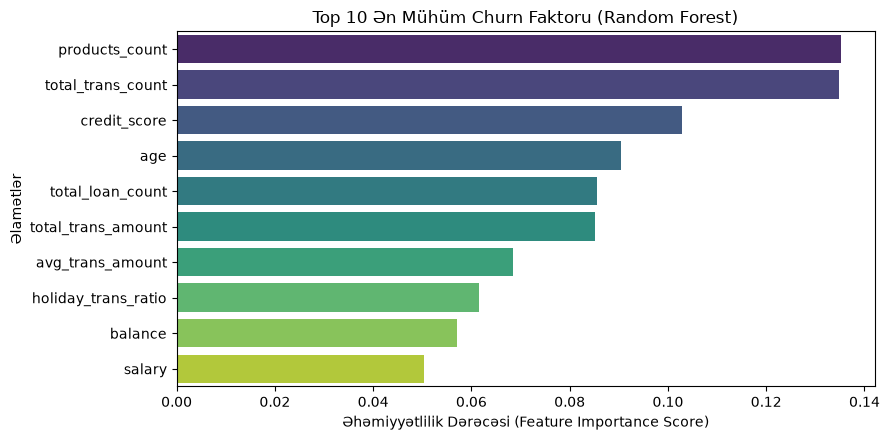

In [30]:
plt.figure(figsize=(9, 4.5))
sns.barplot(x=importance.values, y=importance.index, hue=importance.index, palette="viridis", legend=False)

plt.title("Top 10 Ən Mühüm Churn Faktoru (Random Forest)", fontsize=12)
plt.xlabel("Əhəmiyyətlilik Dərəcəsi (Feature Importance Score)")
plt.ylabel("Əlamətlər")
plt.tight_layout()
plt.show()

## Stage 8: Export

The fitted churn model and validation-selected threshold are saved for the Streamlit churn simulator. A CSV of predictions for all customers is also exported for demonstration/reporting. **The full-customer predictions include training customers and must not be used to report out-of-sample performance.** Only untouched test-set metrics are suitable for that purpose.


Modeli və optimal həddi fayla yazaq

In [31]:
import joblib
from pathlib import Path
MODELS_DIR = PROJECT_ROOT / "models_corrected"
MODELS_DIR.mkdir(parents=True, exist_ok=True)


Bütün 5,000 müştəri üçün Churn ehtimallarının hesablanması

In [32]:
full_probabilities = best_rf_pipeline.predict_proba(X)[:, 1]

Yekun ML Proqnoz Cədvəlinin (Hesabat) Formalaşdırılması

In [33]:
gold_predictions = pd.DataFrame({
    "customer_id": df["customer_id"],
    "churn_probability": full_probabilities.round(4),
    "is_churn_risk": (full_probabilities >= OPTIMAL_THRESHOLD).astype(int),
    "actual_churn": y
})

Layihənin ML çıxarışı olaraq CSV formatında saxlanılması

In [34]:
import json
import joblib
joblib.dump(best_rf_pipeline, MODELS_DIR / "bank_churn_rf_model.pkl")
joblib.dump(OPTIMAL_THRESHOLD, MODELS_DIR / "churn_threshold.pkl")
gold_predictions.to_csv(MODELS_DIR / "gold_churn_predictions.csv", index=False)
metrics = {
    "roc_auc_test": float(roc_auc),
    "pr_auc_test": float(pr_auc),
    "selected_threshold": float(OPTIMAL_THRESHOLD),
    "recall_test_at_threshold": float(recall_score(y_test, y_pred_opt, zero_division=0)),
    "precision_test_at_threshold": float(precision_score(y_test, y_pred_opt, zero_division=0)),
    "f1_test_at_threshold": float(f1_score(y_test, y_pred_opt, zero_division=0)),
    "test_sample_size": int(len(y_test)),
    "selection_method": "validation ROC-AUC for depth; business-selected threshold of 0.35 to prioritize recall"
}
(MODELS_DIR / "evaluation_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Outputs saved to:", MODELS_DIR)
print(metrics)


Outputs saved to: /workspaces/Bank_Analysis/models_corrected
{'roc_auc_test': 0.805820243678503, 'pr_auc_test': 0.5136519959056339, 'selected_threshold': 0.35, 'recall_test_at_threshold': 0.8811881188118812, 'precision_test_at_threshold': 0.34099616858237547, 'f1_test_at_threshold': 0.49171270718232046, 'test_sample_size': 1000, 'selection_method': 'validation ROC-AUC for depth; business-selected threshold of 0.35 to prioritize recall'}



# II Hissə — Kredit Satışlarının Proqnozlaşdırılması

## Məqsəd

2026-cı ilin iyul ayı üçün hər filial üzrə kredit satışlarının sayını və ümumi məbləğini proqnozlaşdırmaq.

**Biznes qaydası:** Təsdiqlənmiş kredit müraciətləri kredit satışı kimi qəbul edilir.

**Tarixi məlumatlar:** Yanvar–iyun 2026.

**Proqnoz dövrü:** İyul 2026.

## Proqnozlaşdırılacaq göstəricilər

- Filial üzrə satılan kreditlərin sayı
- Filial üzrə kredit satışlarının ümumi məbləği (AZN)


#### Silver kredit məlumatlarını yoxlayaq

In [35]:
import pandas as pd

loans_df = pd.read_csv(DATA_DIR / "silver_loans.csv")

print("Sətir sayı:", len(loans_df))
print("\nSütunlar:")
print(loans_df.columns.tolist())

print("\nKredit statusları:")
print(loans_df["status"].value_counts(dropna=False))

print("\nTarix aralığı:")
print(loans_df["application_date"].min())
print(loans_df["application_date"].max())

Sətir sayı: 6876

Sütunlar:
['customer_id', 'age', 'gender', 'city', 'branch', 'tenure_years', 'credit_score', 'balance', 'salary', 'products_count', 'has_card', 'is_active', 'churned', 'loan_id', 'application_date', 'product_type', 'amount', 'term_months', 'interest_rate', 'status', 'rejection_reason', 'defaulted', 'merge_date', 'is_holiday', 'holiday_name', 'is_weekend', 'is_workday', 'is_pre_holiday']

Kredit statusları:
status
təsdiqləndi    2975
NaN            2076
rədd edildi    1825
Name: count, dtype: int64

Tarix aralığı:
2026-01-01
2026-06-30


##### Filiallar üzrə aylıq kredit satışlarını hesablayaq

In [36]:
# Yalnız təsdiqlənmiş kreditləri seçirik
sales_df = loans_df[
    (loans_df["status"] == "təsdiqləndi") &
    (loans_df["loan_id"].notna())
].copy()

# Tarix və məbləğ sütunlarını hazırlayırıq
sales_df["application_date"] = pd.to_datetime(
    sales_df["application_date"]
)

sales_df["amount"] = pd.to_numeric(
    sales_df["amount"], errors="coerce"
)

# Hər kreditin yalnız bir dəfə sayılmasını təmin edirik
sales_df = sales_df.drop_duplicates(subset=["loan_id"])

# Aylıq dövr sütunu yaradırıq
sales_df["month"] = sales_df["application_date"].dt.to_period("M")

# Filiallar üzrə aylıq satışları hesablayırıq
monthly_sales = (
    sales_df.groupby(["branch", "month"])
    .agg(
        kredit_sayi=("loan_id", "nunique"),
        satis_meblegi_azn=("amount", "sum")
    )
    .reset_index()
    .sort_values(["branch", "month"])
)

print("Təsdiqlənmiş unikal kredit sayı:", len(sales_df))
print("Filial sayı:", monthly_sales["branch"].nunique())

display(monthly_sales.head(15))

Təsdiqlənmiş unikal kredit sayı: 2975
Filial sayı: 12


,branch,month,kredit_sayi,satis_meblegi_azn
0,binəqədi,2026-01,48,647194.93
1,binəqədi,2026-02,53,947505.86
2,binəqədi,2026-03,38,370297.05
3,binəqədi,2026-04,48,665047.35
4,binəqədi,2026-05,49,765638.05
5,binəqədi,2026-06,55,929749.38
6,gəncə mərkəz,2026-01,68,738920.98
7,gəncə mərkəz,2026-02,84,1092125.90
8,gəncə mərkəz,2026-03,44,592580.52
9,gəncə mərkəz,2026-04,63,712182.90


##### Hər filialda 6 aylıq məlumat varmı?

In [37]:
# Hər filial üzrə neçə aylıq məlumat olduğunu yoxlayırıq
month_check = (
    monthly_sales.groupby("branch")
    .agg(
        ay_sayi=("month", "nunique"),
        umumi_kredit_sayi=("kredit_sayi", "sum"),
        umumi_satis_azn=("satis_meblegi_azn", "sum")
    )
    .reset_index()
)

display(month_check)

print("\nGözlənilən sətir sayı:", 12 * 6)
print("Faktiki sətir sayı:", len(monthly_sales))

print(
    "6 aydan az məlumatı olan filial sayı:",
    (month_check["ay_sayi"] < 6).sum()
)

,branch,ay_sayi,umumi_kredit_sayi,umumi_satis_azn
0,binəqədi,6,291,4325432.62
1,gəncə mərkəz,6,367,4839256.31
2,lənkəran mərkəz,6,173,1664407.72
3,mingəçevir mərkəz,6,179,91554313.78
4,naxçıvan mərkəz,6,148,2301454.19
5,nərimanov,6,247,3143357.73
6,nəsimi,6,325,3897665.26
7,sumqayıt mərkəz,6,263,3590180.22
8,səbail,6,293,3909777.34
9,xətai,6,261,4286111.49



Gözlənilən sətir sayı: 72
Faktiki sətir sayı: 72
6 aydan az məlumatı olan filial sayı: 0


##### Proqnoz modelini keçmiş məlumatlarla yoxlayaq

In [38]:
import numpy as np
from sklearn.metrics import mean_absolute_error

# Yanvar–may: keçmiş məlumatlar
train_sales = monthly_sales[
    monthly_sales["month"] < pd.Period("2026-06")
].copy()

# İyun: yoxlama ayı
test_sales = monthly_sales[
    monthly_sales["month"] == pd.Period("2026-06")
].copy()

results = []

for branch in monthly_sales["branch"].unique():
    history = train_sales[
        train_sales["branch"] == branch
    ].sort_values("month")

    actual = test_sales[
        test_sales["branch"] == branch
    ]

    # Model 1: Son 3 ayın ortalaması
    pred_3 = history["kredit_sayi"].tail(3).mean()

    # Model 2: Son 5 ayın ortalaması
    pred_5 = history["kredit_sayi"].mean()

    results.append({
        "branch": branch,
        "faktiki_iyun": actual["kredit_sayi"].iloc[0],
        "proqnoz_3_ay": pred_3,
        "proqnoz_5_ay": pred_5
    })

comparison_df = pd.DataFrame(results)

mae_3 = mean_absolute_error(
    comparison_df["faktiki_iyun"],
    comparison_df["proqnoz_3_ay"]
)

mae_5 = mean_absolute_error(
    comparison_df["faktiki_iyun"],
    comparison_df["proqnoz_5_ay"]
)

display(comparison_df.round(2))

print(f"\nSon 3 ayın ortalaması — MAE: {mae_3:.2f}")
print(f"Son 5 ayın ortalaması — MAE: {mae_5:.2f}")

,branch,faktiki_iyun,proqnoz_3_ay,proqnoz_5_ay
0,binəqədi,55,45.00,47.2
1,gəncə mərkəz,57,52.67,62.0
2,lənkəran mərkəz,25,28.67,29.6
3,mingəçevir mərkəz,35,24.67,28.8
4,naxçıvan mərkəz,33,18.67,23.0
5,nərimanov,31,39.33,43.2
6,nəsimi,52,50.67,54.6
7,sumqayıt mərkəz,52,39.67,42.2
8,səbail,48,47.00,49.0
9,xətai,44,39.33,43.4



Son 3 ayın ortalaması — MAE: 6.56
Son 5 ayın ortalaması — MAE: 6.12


##### Kredit satış məbləğini də yoxlayaq

In [39]:
amount_results = []

for branch in monthly_sales["branch"].unique():
    history = train_sales[
        train_sales["branch"] == branch
    ].sort_values("month")

    actual = test_sales[
        test_sales["branch"] == branch
    ]

    amount_results.append({
        "branch": branch,
        "faktiki_iyun_azn": actual["satis_meblegi_azn"].iloc[0],
        "proqnoz_3_ay_azn": history["satis_meblegi_azn"].tail(3).mean(),
        "proqnoz_5_ay_azn": history["satis_meblegi_azn"].mean()
    })

amount_comparison = pd.DataFrame(amount_results)

amount_mae_3 = mean_absolute_error(
    amount_comparison["faktiki_iyun_azn"],
    amount_comparison["proqnoz_3_ay_azn"]
)

amount_mae_5 = mean_absolute_error(
    amount_comparison["faktiki_iyun_azn"],
    amount_comparison["proqnoz_5_ay_azn"]
)

display(amount_comparison.round(2))

print(f"\nSon 3 ayın ortalaması — MAE: {amount_mae_3:,.2f} AZN")
print(f"Son 5 ayın ortalaması — MAE: {amount_mae_5:,.2f} AZN")

,branch,faktiki_iyun_azn,proqnoz_3_ay_azn,proqnoz_5_ay_azn
0,binəqədi,929749.38,600327.48,679136.65
1,gəncə mərkəz,1164465.08,614581.45,734958.25
2,lənkəran mərkəz,168387.88,302181.44,299203.97
3,mingəçevir mərkəz,89450423.00,326219.73,420778.16
4,naxçıvan mərkəz,627910.26,271697.39,334708.79
5,nərimanov,335240.03,518439.19,561623.54
6,nəsimi,735180.10,513826.44,632497.03
7,sumqayıt mərkəz,738106.09,569104.21,570414.83
8,səbail,790353.57,617455.61,623884.75
9,xətai,482648.82,739320.56,760692.53



Son 3 ayın ortalaması — MAE: 7,636,418.16 AZN
Son 5 ayın ortalaması — MAE: 7,609,103.97 AZN


##### Mingəçevir filialındakı böyük kreditləri yoxlayaq

In [40]:
# Mingəçevir filialının iyun ayındakı ən böyük kreditləri
mingecevir_june = sales_df[
    (sales_df["branch"] == "mingəçevir mərkəz") &
    (sales_df["month"] == pd.Period("2026-06"))
].copy()

display(
    mingecevir_june[
        ["loan_id", "application_date", "product_type", "amount"]
    ]
    .sort_values("amount", ascending=False)
    .head(10)
)

print("İyun kredit sayı:", len(mingecevir_june))
print("İyun satış məbləği:", f"{mingecevir_june['amount'].sum():,.2f} AZN")
print("Ən böyük kredit:", f"{mingecevir_june['amount'].max():,.2f} AZN")

,loan_id,application_date,product_type,amount
4590,l004485,2026-06-17,istehlak krediti,88888888.00
1326,l004088,2026-06-02,ipoteka,122458.34
4653,l004738,2026-06-28,ipoteka,103250.36
4339,l004064,2026-06-01,ipoteka,84754.22
81,l004183,2026-06-05,ipoteka,43064.28
6377,l004272,2026-06-08,ipoteka,40104.63
1934,l004258,2026-06-08,avtomobil krediti,34626.80
3414,l004479,2026-06-17,avtomobil krediti,14223.95
208,l004655,2026-06-25,istehlak krediti,10570.43
5374,l004341,2026-06-10,istehlak krediti,9163.72


İyun kredit sayı: 35
İyun satış məbləği: 89,450,423.00 AZN
Ən böyük kredit: 88,888,888.00 AZN


##### Bu məbləğ istehlak krediti üçün son dərəcə qeyri-adidir. məlumatın yaradılması və ya daxil edilməsi zamanı səhv ola bilər.

##### Proqnoz məlumatından qeyri-adi krediti çıxaraq

In [41]:
# Xam və əvvəlki məlumatları dəyişmirik
forecast_sales_df = sales_df[
    sales_df["loan_id"] != "l004485"
].copy()

# Filiallar üzrə aylıq satışları yenidən hesablayırıq
monthly_sales_clean = (
    forecast_sales_df.groupby(["branch", "month"])
    .agg(
        kredit_sayi=("loan_id", "nunique"),
        satis_meblegi_azn=("amount", "sum")
    )
    .reset_index()
    .sort_values(["branch", "month"])
)

print("Orijinal təsdiqlənmiş kredit sayı:", len(sales_df))
print("Proqnoz üçün kredit sayı:", len(forecast_sales_df))

print("\nMingəçevir — iyun ayı:")
display(
    monthly_sales_clean[
        (monthly_sales_clean["branch"] == "mingəçevir mərkəz") &
        (monthly_sales_clean["month"] == pd.Period("2026-06"))
    ]
)

Orijinal təsdiqlənmiş kredit sayı: 2975
Proqnoz üçün kredit sayı: 2974

Mingəçevir — iyun ayı:


,branch,month,kredit_sayi,satis_meblegi_azn
23,mingəçevir mərkəz,2026-06,34,561535.0


##### Təmizlənmiş məlumatlarla proqnoz xətasını yenidən hesablayaq

In [42]:
from sklearn.metrics import mean_absolute_error

neticeler = []

for branch in monthly_sales_clean["branch"].unique():

    filial = monthly_sales_clean[
        monthly_sales_clean["branch"] == branch
    ].sort_values("month")

    kecmis = filial[
        filial["month"] < pd.Period("2026-06")
    ]

    iyun = filial[
        filial["month"] == pd.Period("2026-06")
    ].iloc[0]

    neticeler.append({
        "branch": branch,
        "faktiki_say": iyun["kredit_sayi"],
        "say_3_ay": kecmis["kredit_sayi"].tail(3).mean(),
        "say_5_ay": kecmis["kredit_sayi"].mean(),
        "faktiki_mebleg": iyun["satis_meblegi_azn"],
        "mebleg_3_ay": kecmis["satis_meblegi_azn"].tail(3).mean(),
        "mebleg_5_ay": kecmis["satis_meblegi_azn"].mean()
    })

yoxlama_df = pd.DataFrame(neticeler)

print("KREDİT SAYI ÜZRƏ MAE")
print(
    "Son 3 ay:",
    round(mean_absolute_error(
        yoxlama_df["faktiki_say"],
        yoxlama_df["say_3_ay"]
    ), 2)
)
print(
    "Son 5 ay:",
    round(mean_absolute_error(
        yoxlama_df["faktiki_say"],
        yoxlama_df["say_5_ay"]
    ), 2)
)

print("\nSATIŞ MƏBLƏĞİ ÜZRƏ MAE (AZN)")
print(
    "Son 3 ay:",
    round(mean_absolute_error(
        yoxlama_df["faktiki_mebleg"],
        yoxlama_df["mebleg_3_ay"]
    ), 2)
)
print(
    "Son 5 ay:",
    round(mean_absolute_error(
        yoxlama_df["faktiki_mebleg"],
        yoxlama_df["mebleg_5_ay"]
    ), 2)
)

KREDİT SAYI ÜZRƏ MAE
Son 3 ay: 6.47
Son 5 ay: 6.03

SATIŞ MƏBLƏĞİ ÜZRƏ MAE (AZN)
Son 3 ay: 229010.83
Son 5 ay: 201696.64


İyul 2026 üçün kredit satış proqnozunu hazırlayaq

In [43]:
# İyul 2026 üçün filiallar üzrə kredit satış proqnozu
proqnozlar = []

for branch in monthly_sales_clean["branch"].unique():

    filial = monthly_sales_clean[
        monthly_sales_clean["branch"] == branch
    ].sort_values("month")

    son_5_ay = filial.tail(5)

    proqnozlar.append({
        "filial": branch,
        "proqnoz_ayi": "2026-07",
        "kredit_sayi_proqnozu": round(
            son_5_ay["kredit_sayi"].mean()
        ),
        "satis_meblegi_proqnozu_azn": round(
            son_5_ay["satis_meblegi_azn"].mean(), 2
        )
    })

iyul_proqnozu = pd.DataFrame(proqnozlar)

iyul_proqnozu = iyul_proqnozu.sort_values(
    "satis_meblegi_proqnozu_azn",
    ascending=False
).reset_index(drop=True)

display(iyul_proqnozu)

print("\nİYUL 2026 — ÜMUMİ PROQNOZ")
print(
    "Kredit sayı:",
    iyul_proqnozu["kredit_sayi_proqnozu"].sum()
)
print(
    "Satış məbləği:",
    f"{iyul_proqnozu['satis_meblegi_proqnozu_azn'].sum():,.2f} AZN"
)

,filial,proqnoz_ayi,kredit_sayi_proqnozu,satis_meblegi_proqnozu_azn
0,gəncə mərkəz,2026-07,60,820067.07
1,binəqədi,2026-07,49,735647.54
2,xətai,2026-07,46,731318.38
3,yasamal,2026-07,45,659500.89
4,səbail,2026-07,48,640869.28
5,sumqayıt mərkəz,2026-07,45,637879.60
6,nəsimi,2026-07,53,608424.38
7,nərimanov,2026-07,42,517993.98
8,mingəçevir mərkəz,2026-07,30,441078.82
9,naxçıvan mərkəz,2026-07,22,379522.16



İYUL 2026 — ÜMUMİ PROQNOZ
Kredit sayı: 493
Satış məbləği: 6,811,157.15 AZN


##### Proqnozu CSV faylına yadda saxlayaq

In [44]:
# Proqnoz nəticələrini ayrıca faylda saxlayırıq
OUTPUT_DIR = PROJECT_ROOT / "models_corrected"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / "loan_sales_forecast_july_2026.csv"

iyul_proqnozu.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Proqnoz faylı yaradıldı:")
print(output_path)

print("\nYadda saxlanılan filial sayı:", len(iyul_proqnozu))

Proqnoz faylı yaradıldı:
/workspaces/Bank_Analysis/models_corrected/loan_sales_forecast_july_2026.csv

Yadda saxlanılan filial sayı: 12



## Kredit satışları üçün Machine Learning modellərinin qurulması

Bu mərhələdə kredit satışlarının proqnozlaşdırılması üçün müxtəlif modellər qurulur və müqayisə edilir.

İstifadə ediləcək üsullar:
- Hərəkətli ortalama (Baseline)
- Linear Regression


Modellər zaman ardıcıllığı qorunmaqla qiymətləndiriləcək. Əsas qiymətləndirmə göstəricisi MAE olacaq.

Məqsəd iyul 2026 üçün filiallar üzrə kredit satışlarının sayını və məbləğini mümkün qədər etibarlı proqnozlaşdırmaqdır.


##### Model üçün xüsusiyyətləri (features) hazırlayaq

In [45]:
# Filiallar üzrə aylıq məlumatları ML üçün hazırlayırıq
ml_sales = monthly_sales_clean.copy()

# Ayı rəqəm formasına çeviririk
ml_sales["ay_nomresi"] = ml_sales["month"].dt.month

# Filialları rəqəmsal sütunlara çeviririk
ml_sales = pd.get_dummies(
    ml_sales,
    columns=["branch"],
    dtype=int
)

print("ML üçün məlumat ölçüsü:", ml_sales.shape)
print("\nSütunlar:")
print(ml_sales.columns.tolist())

display(ml_sales.head())

ML üçün məlumat ölçüsü: (72, 16)

Sütunlar:
['month', 'kredit_sayi', 'satis_meblegi_azn', 'ay_nomresi', 'branch_binəqədi', 'branch_gəncə mərkəz', 'branch_lənkəran mərkəz', 'branch_mingəçevir mərkəz', 'branch_naxçıvan mərkəz', 'branch_nərimanov', 'branch_nəsimi', 'branch_sumqayıt mərkəz', 'branch_səbail', 'branch_xətai', 'branch_yasamal', 'branch_şəki mərkəz']


,month,kredit_sayi,satis_meblegi_azn,ay_nomresi,branch_binəqədi,branch_gəncə mərkəz,branch_lənkəran mərkəz,branch_mingəçevir mərkəz,branch_naxçıvan mərkəz,branch_nərimanov,branch_nəsimi,branch_sumqayıt mərkəz,branch_səbail,branch_xətai,branch_yasamal,branch_şəki mərkəz
0,2026-01,48,647194.93,1,1,0,0,0,0,0,0,0,0,0,0,0
1,2026-02,53,947505.86,2,1,0,0,0,0,0,0,0,0,0,0,0
2,2026-03,38,370297.05,3,1,0,0,0,0,0,0,0,0,0,0,0
3,2026-04,48,665047.35,4,1,0,0,0,0,0,0,0,0,0,0,0
4,2026-05,49,765638.05,5,1,0,0,0,0,0,0,0,0,0,0,0


##### Məlumatları tarixə görə ayıraq

In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# İyun ayını test üçün saxlayırıq
train_ml = ml_sales[
    ml_sales["month"] < pd.Period("2026-06")
].copy()

test_ml = ml_sales[
    ml_sales["month"] == pd.Period("2026-06")
].copy()

# Proqnoz üçün istifadə ediləcək sütunlar
feature_cols = [
    col for col in ml_sales.columns
    if col.startswith("branch_") or col == "ay_nomresi"
]

X_train = train_ml[feature_cols]
X_test = test_ml[feature_cols]

# Birinci hədəfimiz: kredit satışlarının sayı
y_train = train_ml["kredit_sayi"]
y_test = test_ml["kredit_sayi"]

print("Train müşahidələri:", len(X_train))
print("Test müşahidələri:", len(X_test))
print("Feature sayı:", len(feature_cols))

Train müşahidələri: 60
Test müşahidələri: 12
Feature sayı: 13


##### Linear Regression ilə kredit sayını proqnozlaşdıraq

In [47]:
# Linear Regression modelini öyrədirik
lr_count_model = LinearRegression()
lr_count_model.fit(X_train, y_train)

# İyun ayı üçün kredit sayını proqnozlaşdırırıq
lr_count_pred = lr_count_model.predict(X_test)

# Modelin xətasını hesablayırıq
lr_count_mae = mean_absolute_error(y_test, lr_count_pred)

print(f"Linear Regression — Kredit sayı MAE: {lr_count_mae:.2f}")

# Faktiki və proqnoz nəticələrini müqayisə edirik
lr_count_results = pd.DataFrame({
    "filial": monthly_sales_clean.loc[test_ml.index, "branch"].values,
    "faktiki_kredit_sayi": y_test.values,
    "proqnoz_kredit_sayi": lr_count_pred.round(2)
})

display(lr_count_results)

Linear Regression — Kredit sayı MAE: 6.15


,filial,faktiki_kredit_sayi,proqnoz_kredit_sayi
0,binəqədi,55,42.92
1,gəncə mərkəz,57,57.72
2,lənkəran mərkəz,25,25.32
3,mingəçevir mərkəz,34,24.52
4,naxçıvan mərkəz,33,18.72
5,nərimanov,31,38.92
6,nəsimi,52,50.32
7,sumqayıt mərkəz,52,37.92
8,səbail,48,44.73
9,xətai,44,39.12


Model	                        Kredit sayı üzrə MAE
Baseline (5 aylıq ortalama)	                    6.03
Linear Regression	                            6.15

İyun ayı üzrə Baseline bir qədər yaxşı nəticə göstərib.

- MAE — modelin orta hesabla neçə kredit yanıldığını göstərir.
- R² — modelin faktiki satış sayındakı dəyişkənliyi nə dərəcədə izah etdiyini göstərir.
R² üçün:
- 1 — mükəmməl proqnoz.
- 0 — test məlumatlarının ortalamasını proqnozlaşdırmaqla eyni nəticə.
- Mənfi qiymət — test məlumatlarının ortalamasını proqnozlaşdırmaqdan daha zəif nəticə.

##### Hər iki modelin R² göstəricisini hesablayaq

In [48]:
from sklearn.metrics import r2_score

# İyun ayı üzrə faktiki kredit sayı
faktiki = yoxlama_df["faktiki_say"]

# Baseline: son 5 ayın ortalaması
baseline_proqnoz = yoxlama_df["say_5_ay"]

# Linear Regression proqnozu
linear_proqnoz = lr_count_pred

print("KREDİT SAYI ÜZRƏ R²")
print(f"Baseline R²: {r2_score(faktiki, baseline_proqnoz):.4f}")
print(f"Linear Regression R²: {r2_score(y_test, linear_proqnoz):.4f}")

KREDİT SAYI ÜZRƏ R²
Baseline R²: 0.6600
Linear Regression R²: 0.5595


Göstərici	Baseline	Linear Regression
MAE	6.03	6.15
R²	0.6600	0.5595

Nəticə: İyun ayının test məlumatlarında Baseline modeli hər iki göstəriciyə görə daha yaxşıdır.
- R² = 0.66 — Baseline modelinin iyun ayındakı filiallararası kredit sayı dəyişkənliyini nisbətən yaxşı əks etdirdiyini göstərir.
- R² = 0.5595 — Linear Regression da müəyyən proqnoz qabiliyyəti göstərir, lakin Baseline-dan zəifdir.
Bu nəticələrə əsasən, kredit sayı üçün hələlik Baseline modelini seçirik.

##### Satış məbləği üçün Linear Regression

In [50]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Satış məbləğini hədəf dəyişən kimi seçirik
y_train_amount = train_ml["satis_meblegi_azn"]
y_test_amount = test_ml["satis_meblegi_azn"]

# Linear Regression modelini qururuq
lr_amount_model = LinearRegression()

# Yanvar–may məlumatları ilə modeli öyrədirik
lr_amount_model.fit(X_train, y_train_amount)

# İyun ayının satış məbləğini proqnozlaşdırırıq
lr_amount_pred = lr_amount_model.predict(X_test)

# MAE və R² hesablayırıq
lr_amount_mae = mean_absolute_error(
    y_test_amount, lr_amount_pred
)



print("LINEAR REGRESSION — SATIŞ MƏBLƏĞİ")
print(f"MAE: {lr_amount_mae:,.2f} AZN")


# Faktiki və proqnozlaşdırılmış məbləğləri müqayisə edirik
lr_amount_results = pd.DataFrame({
    "filial": test_ml.index.map(
        monthly_sales_clean["branch"]
    ),
    "faktiki_mebleg_azn": y_test_amount.values,
    "proqnoz_mebleg_azn": lr_amount_pred.round(2)
})

display(lr_amount_results)

LINEAR REGRESSION — SATIŞ MƏBLƏĞİ
MAE: 224,615.91 AZN


,filial,faktiki_mebleg_azn,proqnoz_mebleg_azn
0,binəqədi,929749.38,610378.83
1,gəncə mərkəz,1164465.08,666200.43
2,lənkəran mərkəz,168387.88,230446.15
3,mingəçevir mərkəz,561535.00,352020.34
4,naxçıvan mərkəz,627910.26,265950.97
5,nərimanov,335240.03,492865.72
6,nəsimi,735180.10,563739.22
7,sumqayıt mərkəz,738106.09,501657.01
8,səbail,790353.57,555126.94
9,xətai,482648.82,691934.72


In [51]:
from sklearn.metrics import mean_absolute_error, r2_score

# Baseline proqnozlarını test filiallarının sırasına uyğunlaşdırırıq
test_filiallari = monthly_sales_clean.loc[test_ml.index, "branch"].values

baseline_test = pd.DataFrame({
    "branch": test_filiallari
}).merge(
    yoxlama_df[["branch", "say_5_ay", "mebleg_5_ay"]],
    on="branch",
    how="left",
    validate="one_to_one"
)

# Bütün modelləri eyni test məlumatları üzərində müqayisə edirik
muqayise = pd.DataFrame([
    {
        "Göstərici": "Kredit sayı",
        "Model": "Baseline",
        "MAE": mean_absolute_error(y_test, baseline_test["say_5_ay"]),
        "R²": r2_score(y_test, baseline_test["say_5_ay"])
    },
    {
        "Göstərici": "Kredit sayı",
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(y_test, lr_count_pred),
        "R²": r2_score(y_test, lr_count_pred)
    },
    {
        "Göstərici": "Satış məbləği (AZN)",
        "Model": "Baseline",
        "MAE": mean_absolute_error(
            y_test_amount, baseline_test["mebleg_5_ay"]
        ),
        "R²": r2_score(
            y_test_amount, baseline_test["mebleg_5_ay"]
        )
    },
    {
        "Göstərici": "Satış məbləği (AZN)",
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(y_test_amount, lr_amount_pred),
        "R²": r2_score(y_test_amount, lr_amount_pred)
    }
])

display(muqayise.round(4))

,Göstərici,Model,MAE,R²
0,Kredit sayı,Baseline,6.0333,0.6600
1,Kredit sayı,Linear Regression,6.1458,0.5595
2,Satış məbləği (AZN),Baseline,201696.6405,0.2432
3,Satış məbləği (AZN),Linear Regression,224615.9122,0.0187



## Modelin qiymətləndirilməsi və yekun nəticə

### 1. Modellərin müqayisəsi

Kredit satışlarının proqnozlaşdırılması üçün iki üsul müqayisə edilmişdir:

- **Baseline:** Son 5 ayın hər filial üzrə orta satış göstəricisi
- **Linear Regression:** Filial və ay məlumatları əsasında qurulmuş reqressiya modeli

Modellər yanvar–may 2026 məlumatları ilə hazırlanmış, iyun 2026 məlumatları üzərində yoxlanılmışdır.

### 2. Qiymətləndirmə nəticələri

| Göstərici | Model | MAE | R² |
|---|---|---:|---:|
| Kredit sayı | Baseline | 6.03 | 0.6600 |
| Kredit sayı | Linear Regression | 6.15 | 0.5595 |
| Satış məbləği (AZN) | Baseline | 201,696.64 | 0.2432 |
| Satış məbləği (AZN) | Linear Regression | 224,615.91 | 0.0187 |

### 3. Model seçimi

İyun ayı üzrə test nəticələrində Baseline üsulu həm kredit sayı, həm də satış məbləği üzrə Linear Regression modelindən daha aşağı MAE və daha yüksək R² göstərmişdir.

Bu səbəbdən iyul 2026 proqnozu üçün **son 5 ayın ortalaması (Baseline)** üsulu seçilmişdir.

### 4. İyul 2026 üçün proqnoz

12 filial üzrə ümumi proqnoz:

- **Kredit satışlarının sayı:** 493
- **Kredit satışlarının məbləği:** 6,811,157.15 AZN

Proqnoz fevral–iyun 2026 məlumatları əsasında hesablanmışdır.

### 5. Məlumatların hazırlanması və məhdudiyyətlər

- Təsdiqlənmiş kreditlər biznes qaydasına əsasən kredit satışı kimi qəbul edilmişdir.
- Proqnoz məlumatlarından `l004485` nömrəli, 88,888,888 AZN məbləğli qeyri-adi kredit çıxarılmışdır. Orijinal məlumat dəyişdirilməmişdir.
- Məlumatlar yalnız yanvar–iyun 2026 dövrünü əhatə edir.
- Modellərin qiymətləndirilməsi yalnız iyun ayı üzrə aparılmışdır.
- Satış məbləği üzrə R² göstəricilərinin aşağı olması proqnozun məhdud dəqiqliyini göstərir.
- Proqnoz nəticələri faktiki gələcək satışlara zəmanət vermir.

### 6. Yekun

Layihədə kredit satışlarının proqnozlaşdırılması üçün Baseline və Linear Regression üsulları qurulmuş və müqayisə edilmişdir.

Test nəticələrinə əsasən daha yaxşı göstəricilər əldə edən Baseline üsulu seçilmiş, iyul 2026 üçün filiallar üzrə kredit sayı və satış məbləği proqnozlaşdırılmışdır.
